<a href="https://colab.research.google.com/github/adityachauhan5508/capstone-Aditya-Chauhan-/blob/main/CAPSTONE%20by%20Aditya%20Chauhan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Import libraries and create the dataset

In [1]:
# Install Plotly (run if not already installed)
!pip install plotly -q

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

from plotly.subplots import make_subplots
from IPython.display import display

# Create a 24-record e-commerce dataset
data = {
    "Sales": [
        1200, 1500, 600, 4500, 1800, 900,
        4000, 7200, 750, 2700, 1000, 6600,
        1600, 6400, 1600, 3000, 700, 5000,
        2800, 5700, 1300, 1650, 3800, 7200
    ],

    "Quantity": [
        1, 2, 2, 3, 3, 2,
        2, 4, 3, 3, 2, 3,
        2, 4, 4, 3, 2, 2,
        4, 3, 2, 3, 4, 3
    ],

    "Product_Price": [
        1200, 750, 300, 1500, 600, 450,
        2000, 1800, 250, 900, 500, 2200,
        800, 1600, 400, 1000, 350, 2500,
        700, 1900, 650, 550, 950, 2400
    ],

    "Category": [
        "Electronics", "Home", "Fashion", "Electronics", "Home", "Fashion",
        "Electronics", "Electronics", "Fashion", "Home", "Fashion", "Electronics",
        "Home", "Electronics", "Fashion", "Home", "Fashion", "Electronics",
        "Home", "Electronics", "Home", "Fashion", "Home", "Electronics"
    ],

    "Order_Date": pd.to_datetime([
        "2026-01-01", "2026-01-02", "2026-01-03", "2026-01-04", "2026-01-05", "2026-01-06",
        "2026-01-07", "2026-01-08", "2026-01-09", "2026-01-10", "2026-01-11", "2026-01-12",
        "2026-01-13", "2026-01-14", "2026-01-15", "2026-01-16", "2026-01-17", "2026-01-18",
        "2026-01-19", "2026-01-20", "2026-01-21", "2026-01-22", "2026-01-23", "2026-01-24"
    ])
}

df = pd.DataFrame(data)

# Display raw dataset
display(df)

,Sales,Quantity,Product_Price,Category,Order_Date
0,1200,1,1200,Electronics,2026-01-01
1,1500,2,750,Home,2026-01-02
2,600,2,300,Fashion,2026-01-03
3,4500,3,1500,Electronics,2026-01-04
4,1800,3,600,Home,2026-01-05
5,900,2,450,Fashion,2026-01-06
6,4000,2,2000,Electronics,2026-01-07
7,7200,4,1800,Electronics,2026-01-08
8,750,3,250,Fashion,2026-01-09
9,2700,3,900,Home,2026-01-10


2. Explore and inspect the dataset

In [2]:
# 1. Check number of rows and columns
print("Dataset Shape:")
print(df.shape)

# 2. Check column names and data types
print("\nDataset Information:")
df.info()

# 3. Statistical summary of numerical columns
print("\nDescriptive Statistics:")
display(df.describe())

# 4. Frequency distribution of categorical column
print("\nCategory-wise Order Count:")
print(df["Category"].value_counts())

Dataset Shape:
(24, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Sales          24 non-null     int64         
 1   Quantity       24 non-null     int64         
 2   Product_Price  24 non-null     int64         
 3   Category       24 non-null     object        
 4   Order_Date     24 non-null     datetime64[ns]
dtypes: datetime64[ns](1), int64(3), object(1)
memory usage: 1.1+ KB

Descriptive Statistics:


,Sales,Quantity,Product_Price,Order_Date
count,24.000000,24.00000,24.000000,24
mean,3062.500000,2.75000,1093.750000,2026-01-12 12:00:00
min,600.000000,1.00000,250.000000,2026-01-01 00:00:00
25%,1275.000000,2.00000,537.500000,2026-01-06 18:00:00
50%,2250.000000,3.00000,850.000000,2026-01-12 12:00:00
75%,4625.000000,3.00000,1650.000000,2026-01-18 06:00:00
max,7200.000000,4.00000,2500.000000,2026-01-24 00:00:00
std,2237.052117,0.84699,710.681317,NaN



Category-wise Order Count:
Category
Electronics    9
Home           8
Fashion        7
Name: count, dtype: int64


3. Perform correlation analysis

Correlation Matrix:


,Quantity,Product_Price,Sales
Quantity,1.000000,0.094802,0.485894
Product_Price,0.094802,1.000000,0.889468
Sales,0.485894,0.889468,1.000000


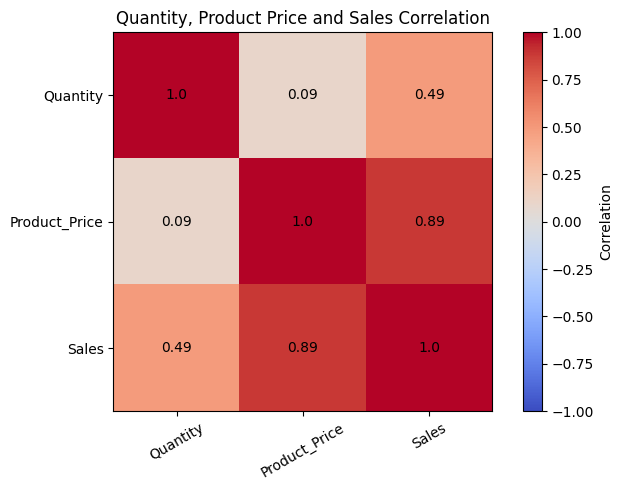

In [3]:
# Calculate correlation
correlation = df[
    ["Quantity", "Product_Price", "Sales"]
].corr()

print("Correlation Matrix:")
display(correlation)

# Visualize correlation using a heatmap
plt.figure(figsize=(7, 5))

plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Correlation")

plt.xticks(range(len(correlation.columns)),
           correlation.columns, rotation=30)

plt.yticks(range(len(correlation.columns)),
           correlation.columns)

# Display correlation values
for i in range(len(correlation.columns)):
    for j in range(len(correlation.columns)):
        plt.text(j, i, round(correlation.iloc[i, j], 2),
                 ha="center", va="center")

plt.title("Quantity, Product Price and Sales Correlation")
plt.tight_layout()
plt.show()

4. Perform groupby analysis

In [4]:
# Group orders by product category
category_summary = df.groupby("Category").agg(
    Average_Quantity=("Quantity", "mean"),
    Average_Product_Price=("Product_Price", "mean"),
    Average_Sales=("Sales", "mean"),
    Order_Count=("Sales", "count")
).round(2)

print("Category-wise Sales Summary:")
display(category_summary)

Category-wise Sales Summary:


,Average_Quantity,Average_Product_Price,Average_Sales,Order_Count
Category,,,,
Electronics,2.78,1900.00,5311.11,9
Fashion,2.57,400.00,1028.57,7
Home,2.88,793.75,2312.50,8


5. Create an interactive dashboard using Plotly

In [5]:
# Calculate category-wise average sales
category_sales = df.groupby("Category")["Sales"].mean().reset_index()

# Create a 2x2 dashboard
fig = make_subplots(
    rows=2,
    cols=2,

    subplot_titles=(
        "Higher Product Prices Are Positively Associated with Sales",
        "Average Sales Differ Across Product Categories",
        "Most Customer Orders Fall in the Lower-to-Mid Sales Range",
        "Sales Across Order Dates"
    ),

    specs=[
        [{"type": "xy"}, {"type": "xy"}],
        [{"type": "xy"}, {"type": "xy"}]
    ],

    vertical_spacing=0.16,
    horizontal_spacing=0.12
)

# CHART 1: Scatter plot (Top-left)
fig.add_trace(
    go.Scatter(
        x=df["Product_Price"],
        y=df["Sales"],
        mode="markers",
        text=df["Category"],
        marker=dict(
            size=12,
            color=df["Quantity"],
            colorscale="Viridis",
            showscale=True,
            colorbar=dict(title="Quantity")
        ),
        name="Orders",
        customdata=df[["Quantity", "Category"]],
        hovertemplate=
        "<b>%{text}</b><br>" +
        "Product Price: %{x}<br>" +
        "Sales: %{y}<br>" +
        "Quantity: %{customdata[0]}<br>" +
        "Category: %{customdata[1]}<extra></extra>"
    ),
    row=1, col=1
)

# CHART 2: Bar chart (Top-right)
fig.add_trace(
    go.Bar(
        x=category_sales["Category"],
        y=category_sales["Sales"],
        text=category_sales["Sales"].round(1),
        textposition="outside",
        name="Average Sales",
        hovertemplate=
        "Category: %{x}<br>" +
        "Average Sales: %{y:.2f}<extra></extra>"
    ),
    row=1, col=2
)

# CHART 3: Histogram (Bottom-left)
fig.add_trace(
    go.Histogram(
        x=df["Sales"],
        nbinsx=5,
        name="Sales Distribution",
        hovertemplate=
        "Sales Range: %{x}<br>" +
        "Number of Orders: %{y}<extra></extra>"
    ),
    row=2, col=1
)

# CHART 4: Line chart (Bottom-right)
date_summary = df.sort_values("Order_Date")

fig.add_trace(
    go.Scatter(
        x=date_summary["Order_Date"],
        y=date_summary["Sales"],
        mode="lines+markers",
        name="Order Sales",
        marker=dict(size=9),
        hovertemplate=
        "Date: %{x|%d %b %Y}<br>" +
        "Sales: %{y}<extra></extra>"
    ),
    row=2, col=2
)

# Axis labels
fig.update_xaxes(title_text="Product Price", row=1, col=1)
fig.update_yaxes(title_text="Sales", row=1, col=1)

fig.update_xaxes(title_text="Category", row=1, col=2)
fig.update_yaxes(title_text="Average Sales", row=1, col=2)

fig.update_xaxes(title_text="Sales", row=2, col=1)
fig.update_yaxes(title_text="Number of Orders", row=2, col=1)

fig.update_xaxes(title_text="Order Date", row=2, col=2)
fig.update_yaxes(title_text="Sales", row=2, col=2)

# Dashboard title and layout
fig.update_layout(
    title=dict(
        text="E-COMMERCE SALES AND CUSTOMER BEHAVIOUR ANALYTICS DASHBOARD",
        x=0.5,
        font=dict(size=22)
    ),
    height=850,
    width=1200,
    template="plotly_white",
    showlegend=True,
    hovermode="closest"
)

# Display interactive dashboard
fig.show()

6. Export the interactive dashboard

In [6]:
# Export complete dashboard
fig.write_html(
    "Ecommerce_Sales_Dashboard.html",
    include_plotlyjs=True
)

print("Dashboard exported successfully!")

Dashboard exported successfully!


In [ ]:
from google.colab import files
files.download("Ecommerce_Sales_Dashboard.html")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

7. Dashboard Reflection
The E-Commerce Sales and Customer Behaviour Analytics Dashboard presents an overview of 24 e-commerce orders based on Sales, Quantity, Product Price, Category, and Order Date. The scatter plot helps examine the strong positive relationship between product price, purchase quantity, and total sales, while the bar chart compares average sales across Electronics, Home, and Fashion categories. The histogram shows the frequency distribution of sales values across orders, and the line chart presents sales in chronological order-date sequence. The correlation matrix and groupby analysis provide additional numerical insights, showing that Electronics achieves the highest average sales due to higher product prices, whereas Fashion sees smaller per-order sales values. Overall, the dashboard helps identify key purchasing and revenue patterns in the dataset, though observations from 24 records should not be generalized to a larger e-commerce store population without further data.